# Task 3: Bankruptcy prediction with the Altman Z-score

Use free data (news APIs or archives, Kaggle news datasets, price data from yfinance or Stooq, financials from company filings). Report results with the metrics where relevant.

**Core:** compute the Z-score (Section 4) for a sample of several firms using one year of financial statements, including several firms that filed for bankruptcy within the following two years. Report how well the score separates the two groups. **Stretch:** replace the fixed Altman weights with a logistic regression fitted on part of the sample, evaluate it on the held-out part, and compare its classification to the original fixed-weight score.


## Report

**Report - Core Part**

We used the public US bankruptcy dataset of Lombardo et al. (2022) and Pellegrino et al. (2024) (github.com/sowide/bankruptcy_dataset). It contains Compustat accounting data (in $ millions) for firms listed on the NYSE and NASDAQ, with one row per firm. A firm is labelled *bankrupt* if it filed for Chapter 7 or Chapter 11 in the year after the fiscal year of its statements; otherwise it is *alive*. We used the latest fiscal year of each firm (fiscal years 2001–2018). The sample has **6,190 firms**, of which **502 (8.1%) went bankrupt**. For each firm we computed the original Altman (1968) Z-score:

$$Z = 1.2\,\frac{WC}{TA} + 1.4\,\frac{RE}{TA} + 3.3\,\frac{EBIT}{TA} + 0.6\,\frac{MVE}{TL} + 1.0\,\frac{Sales}{TA}$$

where WC = current assets − current liabilities, RE = retained earnings, MVE = market value of equity, TL = total liabilities and TA = total assets. The usual zones are *distress* (Z < 1.81), *grey* (1.81–2.99) and *safe* (Z > 2.99).

| Median | Alive | Bankrupt |
|---|---|---|
| WC/TA | 0.19 | -0.00 |
| RE/TA | -0.12 | -0.85 |
| EBIT/TA | 0.04 | -0.07 |
| MVE/TL | 1.90 | 0.24 |
| Sales/TA | 0.86 | 1.04 |
| **Z-score** | **2.27** | **-0.43** |

Four of the five ratios are much worse for firms that went bankrupt. The bankrupt firms have no working capital, large accumulated losses (median RE/TA of −85%), negative operating profit, and equity worth only a quarter of their liabilities. The exception is Sales/TA, which is slightly *higher* for bankrupt firms, so this ratio does not help to separate the groups in this sample. The median Z-score is −0.43 for bankrupt firms against 2.27 for alive firms.

| Altman zone | Share of alive firms | Share of bankrupt firms | Firms | Bankruptcy rate in zone |
|---|---|---|---|---|
| Distress (Z < 1.81) | 43.6% | 80.1% | 2,883 | 13.9% |
| Grey (1.81–2.99) | 16.7% | 10.2% | 1,001 | 5.1% |
| Safe (Z > 2.99) | 39.7% | 9.8% | 2,306 | 2.1% |

| Rule (full sample) | Hit rate (bankrupt flagged) | False alarm (alive flagged) | Accuracy |
|---|---|---|---|
| Z < 1.81 | 80.1% | 43.6% | 58.3% |
| Z < 2.99 | 90.2% | 60.3% | 43.8% |

The score separates the two groups clearly. 80% of the firms that went bankrupt were in the distress zone a year before, and only 10% were in the safe zone. The bankruptcy rate falls steadily across the zones, from 13.9% in the distress zone to 5.1% in the grey zone and 2.1% in the safe zone, so a distress-zone firm is about 6.6 times as likely to fail as a safe-zone firm. The area under the ROC curve (AUC) is **0.72**, where 0.5 means no information and 1 means perfect separation.

The weakness is the **number of false alarms**: 44% of the firms that survived were also in the distress zone. The median surviving firm has negative retained earnings and sits in the grey zone. Two reasons explain this:
- **Different firms from Altman's original sample.** Altman estimated his weights in 1968 on manufacturing firms. Our sample includes many small, young and loss-making firms (technology and biotech, for example) that have low Z-scores but survive by raising new equity.
- **Industry differences in Sales/TA.** The weight on Sales/TA penalises asset-heavy firms, whose ratio depends more on the industry than on credit risk.

The histogram shows a third problem: the Z-score has very fat tails. 15% of the bankrupt firms but also 10% of the surviving firms have Z ≤ −10. These are mostly firms with very small total assets and large accumulated deficits, so RE/TA alone can be below −5. At the other end, 3.5% of surviving firms have Z ≥ 15 because of a very high MVE/TL. A linear score with fixed weights lets one extreme ratio dominate the whole score.

The Z-score is therefore good at **ranking** firms by risk, but the fixed 1.81 cut-off flags far too many healthy firms in a modern, broad sample.

**Report - Stretch Part**

We replaced the fixed Altman weights with a logistic regression on the same five ratios:

$$P(\text{bankrupt}) = \frac{1}{1 + e^{-(b_0 + b_1\,WC/TA + b_2\,RE/TA + b_3\,EBIT/TA + b_4\,MVE/TL + b_5\,Sales/TA)}}$$

The model is fitted on fiscal years 2001–2014 (3,142 firms, 403 bankrupt) and evaluated on the held-out years 2015–2018 (3,048 firms, 99 bankrupt). The split is by time, so the model is always tested on later years than it was fitted on. The ratios have extreme outliers caused by very small denominators. We therefore winsorised them at the 1st and 99th percentiles of the training set and standardised them.

| Ratio | Logit coef. (per 1 sd) | SE | z-stat | Altman weight (on Z, higher = safer) |
|---|---|---|---|---|
| WC/TA | -0.08 | 0.07 | -1.06 | 1.2 |
| RE/TA | +0.08 | 0.09 | +0.89 | 1.4 |
| EBIT/TA | -0.09 | 0.08 | -1.09 | 3.3 |
| **MVE/TL** | **-1.52** | **0.20** | **-7.76** | 0.6 |
| Sales/TA | -0.00 | 0.05 | -0.03 | 1.0 |

A negative coefficient means a higher ratio lowers the probability of bankruptcy. This is the same direction as a positive Altman weight, which raises Z. Once the five ratios are used together, **only market leverage (MVE/TL) is significant**. The four accounting ratios become insignificant, and RE/TA even takes the wrong sign. The ratios are strongly correlated with each other, and the market value of equity already reflects what investors know about the firm's profitability and accumulated losses. The data-driven model therefore puts almost all its weight on the one ratio to which Altman gave the *smallest* weight (0.6).

To compare the two models fairly, we flag the same share of firms with each. We chose the logit cut-off (p > 0.146) on the training set so that it flags as many firms as Z < 1.81 does, and applied both rules once to the test set.

| Held-out test set (2015–2018) | Altman Z < 1.81 | Logistic (p > 0.146) |
|---|---|---|
| Hit rate (bankrupt flagged) | 86.9% | 87.9% |
| False alarm (alive flagged) | 41.4% | 37.2% |
| Accuracy | 59.5% | 63.6% |
| Firms flagged | 1,308 | 1,183 |
| **AUC (test)** | **0.78** | **0.88** |
| AUC (train) | 0.68 | 0.76 |

On the held-out years the logistic model is clearly better. Its AUC is 0.88 against 0.78 for the fixed Altman score. The difference of +0.10 has a 95% bootstrap confidence interval of [+0.04, +0.15], so it is not due to chance. At the Altman cut-off the logistic model catches slightly more of the bankrupt firms (88% vs 87%) while flagging fewer healthy ones (37% vs 41%). The ROC curves show where the gain comes from. The two models are similar at the Altman cut-off, where about 40% of healthy firms are flagged anyway. The large difference is among the firms ranked *most* risky. If we allow only 10% false alarms, the logistic model catches **74%** of the bankrupt firms against only **18%** for the Z-score (53% vs 8% at 5% false alarms). Many firms with the lowest Z-scores are loss-making firms with extreme accounting ratios that still survive. The logistic model ranks firms mainly by market leverage, which identifies the truly distressed firms much better. For a lender or investor who can only act on a short list of the riskiest names, this is the difference that matters.

Both models do better on 2015–2018 than on the training years. The test period has fewer bankruptcies (3.2% vs 12.8%), so the bankrupt firms there may be easier to tell apart from the large group of survivors.

The fixed Altman weights are still useful. They need no estimation, are easy to explain, and still rank firms far better than chance. However, they were set on a 1960s manufacturing sample and do not match today's firms. Re-estimating the weights on recent data mainly shifts weight towards **market leverage**. This matches the later literature (e.g. Shumway, 2001), which finds that market-based variables predict bankruptcy better than accounting ratios.

*Limitations.* The dataset is anonymised and contains far more bankruptcies (8%) than the general population of listed firms, so hit rates and false alarms are not population rates. Only the ranking (AUC) carries over. The label is bankruptcy in the year after the fiscal year, but statements are published a few months after the fiscal year-end, so the real warning period is shorter than a full year.

**Conclusion.** The Altman Z-score separates firms that went bankrupt from survivors well: 80% of the bankrupt firms were in the distress zone a year before, the bankruptcy rate falls from 14% in the distress zone to 2% in the safe zone, and the AUC is 0.72. Its main weakness is a high false-alarm rate in a modern sample of small, loss-making firms. A logistic regression on the same five ratios, fitted on 2001–2014, beats the fixed weights out of sample (AUC 0.88 vs 0.78). Almost all of its predictive power comes from the market value of equity relative to liabilities.

## Code

## 0. Set up

In [1]:
import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

LOCAL_ZIP = "dataset_paper.zip"
URL = "https://github.com/sowide/bankruptcy_dataset/raw/main/dataset_paper.zip"
YEAR = "3"              # "3" = latest fiscal year in each row (the year before the filing)
TRAIN_END = 2014        # fit the logistic model on 2001-2014, test on 2015-2018
SAFE, DISTRESS = 2.99, 1.81
RATIOS = ["WC/TA", "RE/TA", "EBIT/TA", "MVE/TL", "Sales/TA"]
ALTMAN_W = np.array([1.2, 1.4, 3.3, 0.6, 1.0])

## 1. Data

In [2]:
# Pellegrino et al. (2024) / Lombardo et al. (2022): US listed firms (NYSE, NASDAQ), 2001-2018,
# Compustat data in $ millions, one row per firm. status_label = "failed" if the firm filed for
# Chapter 7 or Chapter 11 in the year after the fiscal year; columns prefixed 1_, 2_, 3_ are
# the three fiscal years up to fyear (3_ = fyear, the most recent).
if Path(LOCAL_ZIP).exists():                       # use a local copy if you downloaded it
    z = zipfile.ZipFile(LOCAL_ZIP)
else:
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
raw = pd.concat([pd.read_csv(z.open(f"dataset_paper/financial_{k}.csv"))
                 for k in ["train", "validation", "test"]], ignore_index=True)


def altman_inputs(d, y):
    g = lambda v: d[f"{y}_{v}"]
    return pd.DataFrame({
        "WC/TA": (g("current_assets") - g("total_current_liabilities")) / g("total_assets"),
        "RE/TA": g("retained_earnings") / g("total_assets"),
        "EBIT/TA": g("ebit") / g("total_assets"),
        "MVE/TL": g("market_value") / g("total_liabilities"),
        "Sales/TA": g("net_sales") / g("total_assets"),
    })


ok = (raw[f"{YEAR}_total_assets"] > 0) & (raw[f"{YEAR}_total_liabilities"] > 0)
df = pd.concat([raw.loc[ok, ["cik", "fyear"]],
                altman_inputs(raw[ok], YEAR)], axis=1).reset_index(drop=True)
df["failed"] = (raw.loc[ok, "status_label"] == "failed").astype(int).to_numpy()
df["Z"] = df[RATIOS].to_numpy() @ ALTMAN_W

print(f"Firms: {len(df)} (dropped {(~ok).sum()} with zero assets or liabilities), "
      f"fiscal years {df.fyear.min()}-{df.fyear.max()}")
print(f"Bankrupt next year: {df.failed.sum()} ({df.failed.mean():.1%}); "
      f"alive: {(1 - df.failed).sum()}")

Firms: 6190 (dropped 0 with zero assets or liabilities), fiscal years 2001-2018
Bankrupt next year: 502 (8.1%); alive: 5688


### 2. Core: does the Z-score separate the two groups?

=== Median ratios and Z-score by group ===
          Median, Alive  Median, Bankrupt
WC/TA             0.185            -0.003
RE/TA            -0.116            -0.845
EBIT/TA           0.038            -0.070
MVE/TL            1.896             0.236
Sales/TA          0.862             1.042
Z                 2.266            -0.432

=== Share of each group in the Altman zones ===
group             Alive  Bankrupt  Firms  Bankruptcy rate in zone
zone                                                             
Distress (<1.81)  0.436     0.801   2883                    0.139
Grey (1.81-2.99)  0.167     0.102   1001                    0.051
Safe (>2.99)      0.397     0.098   2306                    0.021

=== Classification, full sample (AUC of -Z = 0.717) ===
                                Z < 1.81  Z < 2.99
Hit rate (bankrupt flagged)        0.801     0.902
False alarm (alive flagged)        0.436     0.603
Accuracy                           0.583     0.438
Type I error (bankrupt 

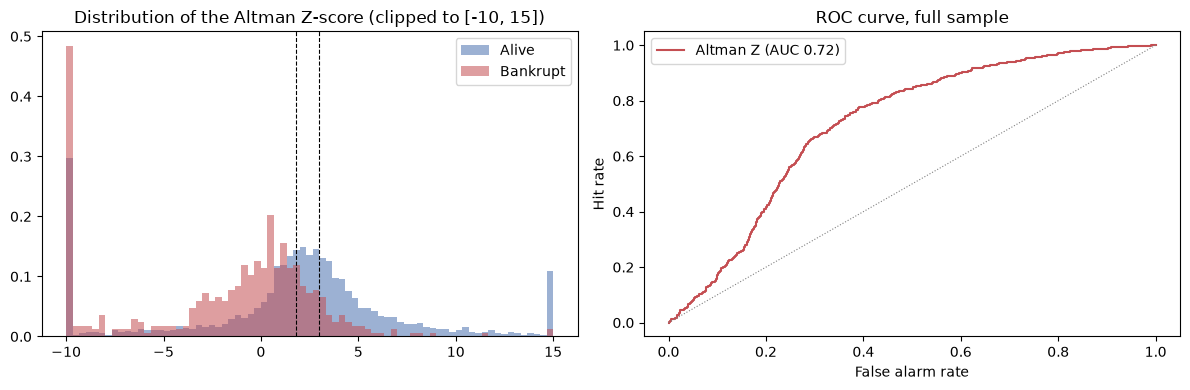

In [3]:
def zone(z):
    return np.select([z < DISTRESS, z < SAFE], ["Distress (<1.81)", "Grey (1.81-2.99)"],
                     "Safe (>2.99)")


df["zone"] = zone(df["Z"])
grp = df.assign(group=np.where(df.failed == 1, "Bankrupt", "Alive"))

desc = grp.groupby("group")[RATIOS + ["Z"]].median().T
desc.columns = [f"Median, {c}" for c in desc.columns]
print("=== Median ratios and Z-score by group ===")
print(desc.round(3).to_string())

zones = pd.crosstab(grp["zone"], grp["group"], normalize="columns").reindex(
    ["Distress (<1.81)", "Grey (1.81-2.99)", "Safe (>2.99)"])
rate = df.groupby("zone")["failed"].agg(["count", "mean"]).reindex(zones.index)
zones["Firms"] = rate["count"]
zones["Bankruptcy rate in zone"] = rate["mean"]
print("\n=== Share of each group in the Altman zones ===")
print(zones.round(3).to_string())


def classify(y, flag):
    tp = ((flag == 1) & (y == 1)).sum(); fn = ((flag == 0) & (y == 1)).sum()
    fp = ((flag == 1) & (y == 0)).sum(); tn = ((flag == 0) & (y == 0)).sum()
    return pd.Series({"Hit rate (bankrupt flagged)": tp / (tp + fn),
                      "False alarm (alive flagged)": fp / (fp + tn),
                      "Accuracy": (tp + tn) / len(y),
                      "Type I error (bankrupt missed)": fn / (tp + fn),
                      "Type II error (alive flagged)": fp / (fp + tn),
                      "Firms flagged": tp + fp})


auc_z = roc_auc_score(df.failed, -df.Z)
core = pd.DataFrame({"Z < 1.81": classify(df.failed, (df.Z < DISTRESS).astype(int)),
                     "Z < 2.99": classify(df.failed, (df.Z < SAFE).astype(int))})
print(f"\n=== Classification, full sample (AUC of -Z = {auc_z:.3f}) ===")
print(core.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(-10, 15, 76)
for lab, c in [("Alive", "#4c72b0"), ("Bankrupt", "#c44e52")]:
    axes[0].hist(grp.loc[grp.group == lab, "Z"].clip(-10, 15), bins=bins, density=True,
                 alpha=0.55, color=c, label=lab)
for x in [DISTRESS, SAFE]:
    axes[0].axvline(x, color="black", lw=0.8, ls="--")
axes[0].set_title("Distribution of the Altman Z-score (clipped to [-10, 15])")
axes[0].legend()
fpr, tpr, _ = roc_curve(df.failed, -df.Z)
axes[1].plot(fpr, tpr, color="#c44e52", label=f"Altman Z (AUC {auc_z:.2f})")
axes[1].plot([0, 1], [0, 1], color="grey", lw=0.8, ls=":")
axes[1].set_xlabel("False alarm rate"); axes[1].set_ylabel("Hit rate")
axes[1].set_title("ROC curve, full sample"); axes[1].legend()
plt.tight_layout()
plt.show()

### 3. Stretch: logistic regression vs fixed Altman weights

=== Logistic regression on 3142 firms (2001-2014, 403 bankrupt) ===
          Logit coef. (per 1 sd)     SE  z-stat  Logit coef. (per unit ratio)  Altman weight (on Z, higher = safer)
WC/TA                     -0.077  0.073  -1.062                        -0.047                                   1.2
RE/TA                      0.081  0.091   0.888                         0.005                                   1.4
EBIT/TA                   -0.088  0.081  -1.092                        -0.106                                   3.3
MVE/TL                    -1.524  0.196  -7.755                        -0.234                                   0.6
Sales/TA                  -0.001  0.053  -0.025                        -0.001                                   1.0

=== Held-out test set: 3048 firms (2015-2018, 99 bankrupt) ===
                                Altman Z < 1.81  Logit p > 0.146
Hit rate (bankrupt flagged)               0.869            0.879
False alarm (alive flagged)               

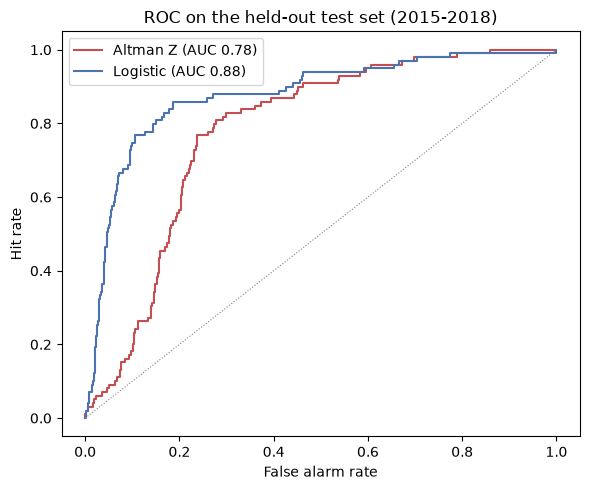

In [4]:
train, test = df[df.fyear <= TRAIN_END], df[df.fyear > TRAIN_END]

# ratios have extreme outliers (tiny denominators): winsorize at the 1st/99th percentile of the TRAIN set
lo, hi = train[RATIOS].quantile(0.01), train[RATIOS].quantile(0.99)
w = lambda d: d[RATIOS].clip(lo, hi, axis=1)
mu, sd = w(train).mean(), w(train).std()
std = lambda d: (w(d) - mu) / sd

logit = LogisticRegression(C=1e6, max_iter=5000).fit(std(train), train.failed)
p_test = logit.predict_proba(std(test))[:, 1]
p_train = logit.predict_proba(std(train))[:, 1]

# standard errors from the inverse of the information matrix X'WX (unpenalised MLE)
Xd = np.column_stack([np.ones(len(train)), std(train).to_numpy()])
cov = np.linalg.inv(Xd.T @ (Xd * (p_train * (1 - p_train))[:, None]))
se = np.sqrt(np.diag(cov))[1:]
coef = pd.DataFrame({
    "Logit coef. (per 1 sd)": logit.coef_[0],
    "SE": se,
    "z-stat": logit.coef_[0] / se,
    "Logit coef. (per unit ratio)": logit.coef_[0] / sd.to_numpy(),
    "Altman weight (on Z, higher = safer)": ALTMAN_W,
}, index=RATIOS)
print(f"=== Logistic regression on {len(train)} firms ({train.fyear.min()}-{TRAIN_END}, "
      f"{train.failed.sum()} bankrupt) ===")
print(coef.round(3).to_string())

# compare at the same number of flagged firms: pick the logit cut-off on the TRAIN set so it flags
# as many train firms as Z < 1.81 does, then apply both rules to the TEST set
share_flagged = (train.Z < DISTRESS).mean()
cut = np.quantile(p_train, 1 - share_flagged)

auc_z_test = roc_auc_score(test.failed, -test.Z)
auc_l_test = roc_auc_score(test.failed, p_test)
auc_l_train = roc_auc_score(train.failed, p_train)
auc_z_train = roc_auc_score(train.failed, -train.Z)

comp = pd.DataFrame({
    "Altman Z < 1.81": classify(test.failed.to_numpy(), (test.Z < DISTRESS).astype(int).to_numpy()),
    f"Logit p > {cut:.3f}": classify(test.failed.to_numpy(), (p_test > cut).astype(int)),
})
comp.loc["AUC (test)"] = [auc_z_test, auc_l_test]
comp.loc["AUC (train)"] = [auc_z_train, auc_l_train]
print(f"\n=== Held-out test set: {len(test)} firms ({TRAIN_END + 1}-{test.fyear.max()}, "
      f"{test.failed.sum()} bankrupt) ===")
print(comp.round(3).to_string())

# bootstrap the AUC difference on the test set
rng = np.random.default_rng(0)
y_t, z_t = test.failed.to_numpy(), -test.Z.to_numpy()
diffs = []
for _ in range(2000):
    i = rng.integers(0, len(y_t), len(y_t))
    if y_t[i].sum() in (0, len(i)):
        continue
    diffs.append(roc_auc_score(y_t[i], p_test[i]) - roc_auc_score(y_t[i], z_t[i]))
lo_ci, hi_ci = np.percentile(diffs, [2.5, 97.5])
print(f"\nAUC(logit) - AUC(Z) on test: {auc_l_test - auc_z_test:+.3f}, "
      f"95% bootstrap CI [{lo_ci:+.3f}, {hi_ci:+.3f}]")

fig, ax = plt.subplots(figsize=(6, 5))
for name, s, c in [(f"Altman Z (AUC {auc_z_test:.2f})", -test.Z, "#c44e52"),
                   (f"Logistic (AUC {auc_l_test:.2f})", p_test, "#4c72b0")]:
    f_, t_, _ = roc_curve(test.failed, s)
    ax.plot(f_, t_, label=name, color=c)
ax.plot([0, 1], [0, 1], color="grey", lw=0.8, ls=":")
ax.set_xlabel("False alarm rate"); ax.set_ylabel("Hit rate")
ax.set_title(f"ROC on the held-out test set ({TRAIN_END + 1}-{test.fyear.max()})")
ax.legend()
plt.tight_layout()
plt.show()